<a href="https://colab.research.google.com/github/EverettParsons/Data_Vis/blob/main/GreenHouseGasses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
import seaborn as sns

In [2]:
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions", skiprows=3)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [3]:
df = df.fillna(df.mean(numeric_only=True))
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [4]:
ghg_array = df.to_numpy()

emissions_only = ghg_array[:,13:].astype(float)

column_sums = np.sum(emissions_only, axis=0)
column_sums_LDC = np.flip(column_sums)

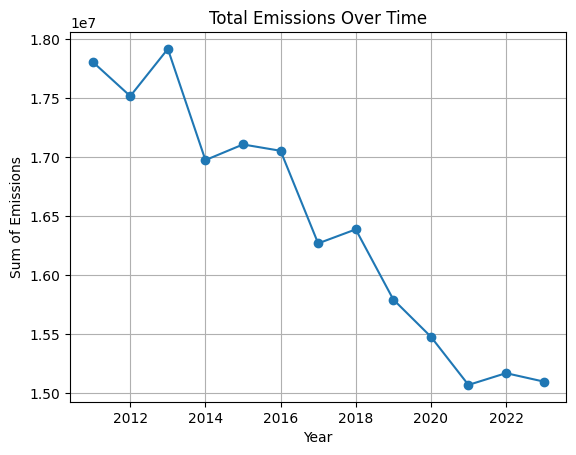

In [5]:
years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

plt.plot(years, column_sums_LDC, marker='o')
plt.title('Total Emissions Over Time')
plt.xlabel('Year')
plt.ylabel('Sum of Emissions')
plt.grid(True)
plt.show()

In [11]:
cols = ['2011 Total reported direct emissions from Local Distribution Companies',
        '2012 Total reported direct emissions from Local Distribution Companies',
        '2013 Total reported direct emissions from Local Distribution Companies',
        '2014 Total reported direct emissions from Local Distribution Companies',
        '2015 Total reported direct emissions from Local Distribution Companies',
        '2016 Total reported direct emissions from Local Distribution Companies',
        '2017 Total reported direct emissions from Local Distribution Companies',
        '2018 Total reported direct emissions from Local Distribution Companies',
        '2018 Total reported direct emissions from Local Distribution Companies',
        '2020 Total reported direct emissions from Local Distribution Companies',
        '2021 Total reported direct emissions from Local Distribution Companies',
        '2022 Total reported direct emissions from Local Distribution Companies',
        '2023 Total reported direct emissions from Local Distribution Companies']
df['Total_Emissions_All_Years'] = df[cols].sum(axis=1)
state_emissions = df.groupby('State where Emissions Occur')['Total_Emissions_All_Years'].sum().reset_index()

state_emissions = state_emissions.sort_values(by='Total_Emissions_All_Years', ascending=False)

states = state_emissions['State where Emissions Occur']
emissions_by_state = state_emissions['Total_Emissions_All_Years']

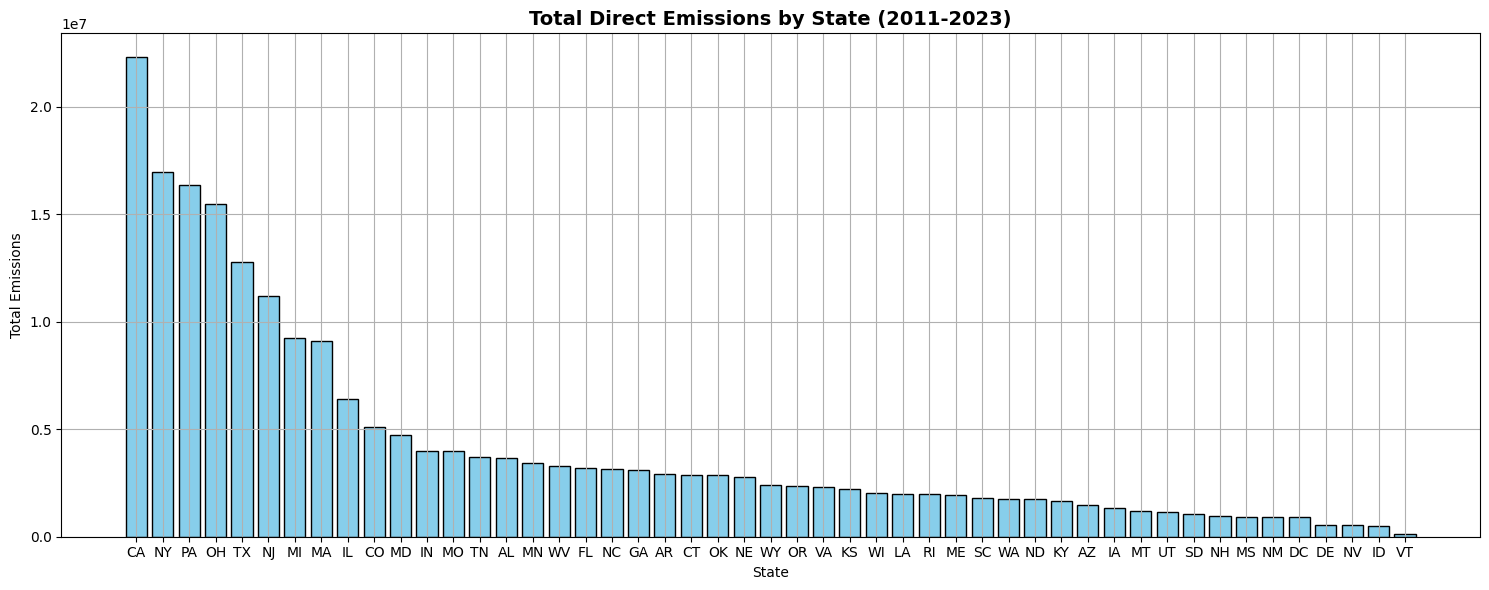

In [12]:
plt.figure(figsize=(15,6))
plt.bar(states, emissions_by_state, color='skyblue', edgecolor='black')

plt.title('Total Direct Emissions by State (2011-2023)', fontsize=14, fontweight='bold')
plt.xlabel('State')
plt.ylabel('Total Emissions')

plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="Transmission Pipelines", skiprows=3)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 21 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   Facility Id                                                       240 non-null    int64  
 1   FRS Id                                                            196 non-null    float64
 2   Facility Name                                                     240 non-null    object 
 3   State where Emissions Occur                                       240 non-null    object 
 4   Reported City                                                     240 non-null    object 
 5   Reported State                                                    240 non-null    object 
 6   Reported Zip Code                                                 240 non-null    int64  
 7   Reported Address                   

In [17]:
df = df.fillna(df.mean(numeric_only=True))
ghg_array = df.to_numpy()
emissions_only = ghg_array[:,13:].astype(float)

In [28]:
column_sums = np.sum(emissions_only, axis=0)
column_sums_TP = np.flip(column_sums)

transmission_total = np.sum(column_sums_TP)
distribution_total = np.sum(column_sums_LDC)

In [29]:
sector_emissions = {"Transmissions Pipeline": transmission_total,
                    "Line Distribution": distribution_total}

Text(0.5, 1.0, 'Emissions by Sector')

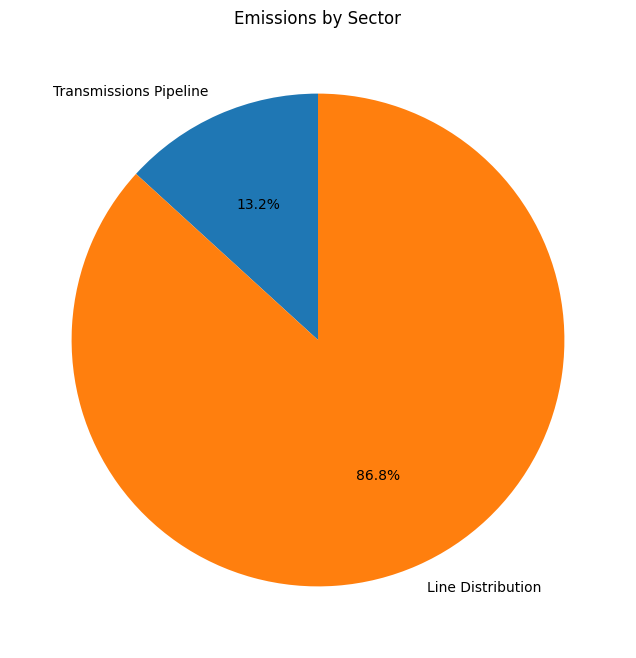

In [37]:
plt.figure(figsize=(8,8))
plt.pie(
    sector_emissions.values(),
    labels=sector_emissions.keys(),
    autopct='%1.1f%%',
    startangle=90)

plt.title("Emissions by Sector")